# Section 4: Validation, Final Comparison, Recommendation & Limitations

**Student ID:** IT24102267  
**Technical Role:** Validation & Final Comparison  
**Module:** IT3091 Machine Learning | **Group:** 2026-DS-58  
**Dataset:** Ames Housing | **Target:** SalePrice | **Seed:** 42  

---

## Section Scope

This notebook provides the final evaluation and model selection layer for the project:

1. **Standardized Re-Evaluation:** Re-trains every candidate model (from the naive baseline to gradient boosting variants) on the exact **shared pipeline output** from Notebook 03, ensuring an apples-to-apples comparison across equal feature spaces.
2. **K-Fold Cross-Validation:** Executes 5-fold cross-validation (`KFold`, `cross_val_score`) across all candidate models to measure out-of-fold stability and variance.
3. **Hyperparameter Tuning:** Conducts systematic tuning (`RandomizedSearchCV`) on the top-performing gradient boosting model.
4. **Leakage-Safe Blending:** Optimizes ensemble blending weights strictly using **out-of-fold validation predictions** to prevent data leakage during weight optimization.
5. **Strict Single-Touch Test Evaluation:** Evaluates final model candidates on the holdout test set **exactly once** at the end of the analysis pipeline.
6. **Validation-Based Interpretability:** Performs residual error analysis and computes permutation feature importances on validation folds to isolate key valuation drivers without evaluating on test data.
7. **Synthesis & Governance:** Concludes with operational deployment recommendations, explicit model limitations, and a responsible AI compliance assessment.

In [1]:
# Imports & Global Configuration
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import KFold, cross_val_score, cross_val_predict, RandomizedSearchCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, make_scorer
from sklearn.inspection import permutation_importance

import xgboost as xgb
import lightgbm as lgb
from catboost import CatBoostRegressor

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)
sns.set_theme(style="whitegrid")

RESULTS_DIR = Path("results")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
print("Validation & Final Comparison environment initialized.")

Validation & Final Comparison environment initialized.


In [2]:
def find_file(filename):
    for p in [Path(filename), Path(f"results/{filename}"), Path(f"/kaggle/input/{filename}")]:
        if p.exists():
            return p
    if Path("/kaggle/input").exists():
        found = list(Path("/kaggle/input").rglob(filename))
        if found:
            return found[0]
    return None

# Load Role C's shared pipeline output -- every model below trains on the SAME features
xtr_path = find_file("X_train_final.csv")
xte_path = find_file("X_test_final.csv")
ytr_path = find_file("y_train_final.csv")
yte_path = find_file("y_test.csv")

if not all([xtr_path, xte_path, ytr_path, yte_path]):
    raise FileNotFoundError(
        "Could not find the shared pipeline output. Run Notebook 03 (Role C) first -- "
        "this notebook needs X_train_final.csv, X_test_final.csv, y_train_final.csv, y_test.csv."
    )

X_train = pd.read_csv(xtr_path)
X_test = pd.read_csv(xte_path)
y_train = pd.read_csv(ytr_path).values.flatten()
y_test = pd.read_csv(yte_path).values.flatten()
print(f"Loaded shared pipeline output: train={X_train.shape}, test={X_test.shape}")
print("Reminder: the test set is not touched again until final evaluation later in this notebook.")

Loaded shared pipeline output: train=(1166, 255), test=(292, 255)
Reminder: the test set is not touched again until final evaluation later in this notebook.


## 4.1 Cross-Validated Comparison of Candidate Models

Model stability and generalization variance are evaluated using 5-fold cross-validation (`KFold`, $k=5$) strictly on the training partition. 

This step addresses a critical gap in earlier iterations where cross-validation modules (`KFold`, `cross_val_score`) were imported but left unexecuted. Evaluating all candidate architectures across identical cross-validation folds ensures that model selection is driven by mean out-of-fold performance and metric stability rather than single-split variance.

In [3]:
def rmse_scorer(y_true, y_pred):
    return np.sqrt(mean_squared_error(y_true, y_pred))
rmse_score = make_scorer(rmse_scorer, greater_is_better=False)

candidates = {
    "Linear Regression": Pipeline([("scaler", StandardScaler()), ("model", LinearRegression())]),
    "Decision Tree": DecisionTreeRegressor(random_state=RANDOM_SEED, max_depth=8, min_samples_leaf=5),
    "Random Forest": RandomForestRegressor(n_estimators=300, random_state=RANDOM_SEED, n_jobs=-1),
    "XGBoost": xgb.XGBRegressor(n_estimators=500, learning_rate=0.03, max_depth=4, subsample=0.8,
                                 colsample_bytree=0.8, random_state=RANDOM_SEED, n_jobs=-1),
    "LightGBM": lgb.LGBMRegressor(n_estimators=500, learning_rate=0.03, num_leaves=31,
                                   random_state=RANDOM_SEED, n_jobs=-1, verbose=-1),
    "CatBoost": CatBoostRegressor(iterations=500, learning_rate=0.03, depth=6, random_state=RANDOM_SEED, verbose=0),
}

kf = KFold(n_splits=5, shuffle=True, random_state=RANDOM_SEED)
cv_rows = []
test_predictions = {}
fitted_models = {}

# --- Median baseline: CV analog computed per fold for a fair comparison row ---
baseline_fold_rmses, baseline_fold_maes, baseline_fold_r2s = [], [], []
for tr_idx, val_idx in kf.split(X_train):
    med = np.median(y_train[tr_idx])
    preds = np.full_like(y_train[val_idx], med, dtype=np.float64)
    baseline_fold_rmses.append(np.sqrt(mean_squared_error(y_train[val_idx], preds)))
    baseline_fold_maes.append(mean_absolute_error(y_train[val_idx], preds))
    baseline_fold_r2s.append(r2_score(y_train[val_idx], preds))

cv_rows.append({
    "Model": "Median Baseline",
    "CV_RMSE_Mean": np.mean(baseline_fold_rmses), "CV_RMSE_Std": np.std(baseline_fold_rmses),
    "CV_MAE_Mean": np.mean(baseline_fold_maes), "CV_R2_Mean": np.mean(baseline_fold_r2s),
})
test_predictions["Median Baseline"] = np.full_like(y_test, np.median(y_train), dtype=np.float64)

# --- Every real candidate model ---
for name, model in candidates.items():
    print(f"Running 5-fold CV for {name}...")
    rmse_folds = -cross_val_score(model, X_train, y_train, cv=kf, scoring=rmse_score, n_jobs=1)
    mae_folds = -cross_val_score(model, X_train, y_train, cv=kf, scoring="neg_mean_absolute_error", n_jobs=1)
    r2_folds = cross_val_score(model, X_train, y_train, cv=kf, scoring="r2", n_jobs=1)

    cv_rows.append({
        "Model": name,
        "CV_RMSE_Mean": rmse_folds.mean(), "CV_RMSE_Std": rmse_folds.std(),
        "CV_MAE_Mean": mae_folds.mean(), "CV_R2_Mean": r2_folds.mean(),
    })

    model.fit(X_train, y_train)
    fitted_models[name] = model
    test_predictions[name] = model.predict(X_test)

cv_summary = pd.DataFrame(cv_rows)
print("\n--- Cross-Validated Performance (training folds only, test set untouched) ---")
display(cv_summary)

Running 5-fold CV for Linear Regression...
Running 5-fold CV for Decision Tree...
Running 5-fold CV for Random Forest...
Running 5-fold CV for XGBoost...
Running 5-fold CV for LightGBM...
Running 5-fold CV for CatBoost...

--- Cross-Validated Performance (training folds only, test set untouched) ---


,Model,CV_RMSE_Mean,CV_RMSE_Std,CV_MAE_Mean,CV_R2_Mean
0,Median Baseline,79047.229801,1566.791544,54666.798672,-0.047077
1,Linear Regression,30071.668749,3354.261116,19448.741327,0.845662
2,Decision Tree,36096.869409,3456.040869,23473.892023,0.779092
3,Random Forest,25539.764522,1589.695997,16369.365026,0.889607
4,XGBoost,22681.833351,1801.277057,14224.396680,0.912601
5,LightGBM,24792.836810,653.264168,15394.929524,0.896720
6,CatBoost,22540.635814,1816.842074,14023.338726,0.913685


## 4.2 Limited Hyperparameter Tuning

In alignment with the project plan's scope, hyperparameter optimization focuses on targeted exploration rather than an exhaustive grid search. A constrained `RandomizedSearchCV` (15 iterations, 5-fold cross-validation) is applied to optimize key XGBoost parameters:

* `max_depth` (tree complexity)
* `learning_rate` (shrinkage factor)
* `n_estimators` (number of boosting rounds)
* `subsample` and `colsample_bytree` (stochastic regularization)

This limited search space strikes an appropriate balance between preventing overfitting and improving predictive performance within the project's computational budget.

In [4]:
param_dist = {
    "n_estimators": [300, 500, 800],
    "max_depth": [3, 4, 5, 6],
    "learning_rate": [0.01, 0.03, 0.05, 0.1],
    "subsample": [0.7, 0.8, 1.0],
    "colsample_bytree": [0.7, 0.8, 1.0],
}

search = RandomizedSearchCV(
    xgb.XGBRegressor(random_state=RANDOM_SEED, n_jobs=-1),
    param_distributions=param_dist,
    n_iter=15,
    cv=kf,
    scoring=rmse_score,
    random_state=RANDOM_SEED,
    n_jobs=1,
)
search.fit(X_train, y_train)
print("Best hyperparameters found:", search.best_params_)
print(f"Best CV RMSE: ${-search.best_score_:,.2f}")

tuned_model = search.best_estimator_
tuned_model.fit(X_train, y_train)
fitted_models["Tuned XGBoost"] = tuned_model
test_predictions["Tuned XGBoost"] = tuned_model.predict(X_test)

tuned_rmse_folds = -cross_val_score(tuned_model, X_train, y_train, cv=kf, scoring=rmse_score)
tuned_mae_folds = -cross_val_score(tuned_model, X_train, y_train, cv=kf, scoring="neg_mean_absolute_error")
tuned_r2_folds = cross_val_score(tuned_model, X_train, y_train, cv=kf, scoring="r2")

cv_rows.append({
    "Model": "Tuned XGBoost",
    "CV_RMSE_Mean": tuned_rmse_folds.mean(), "CV_RMSE_Std": tuned_rmse_folds.std(),
    "CV_MAE_Mean": tuned_mae_folds.mean(), "CV_R2_Mean": tuned_r2_folds.mean(),
})
cv_summary = pd.DataFrame(cv_rows)
display(cv_summary)

Best hyperparameters found: {'subsample': 0.7, 'n_estimators': 500, 'max_depth': 3, 'learning_rate': 0.03, 'colsample_bytree': 0.7}
Best CV RMSE: $21,873.48


,Model,CV_RMSE_Mean,CV_RMSE_Std,CV_MAE_Mean,CV_R2_Mean
0,Median Baseline,79047.229801,1566.791544,54666.798672,-0.047077
1,Linear Regression,30071.668749,3354.261116,19448.741327,0.845662
2,Decision Tree,36096.869409,3456.040869,23473.892023,0.779092
3,Random Forest,25539.764522,1589.695997,16369.365026,0.889607
4,XGBoost,22681.833351,1801.277057,14224.396680,0.912601
5,LightGBM,24792.836810,653.264168,15394.929524,0.896720
6,CatBoost,22540.635814,1816.842074,14023.338726,0.913685
7,Tuned XGBoost,21873.480350,1322.062547,13970.213477,0.919082


## 4.3 Ensemble Blending via Out-of-Fold Optimization

Rather than using static, unvalidated blending weights (e.g., equal or arbitrary weightings), the ensemble weights are optimized empirically through a leakage-safe protocol:

1. **Out-of-Fold (OOF) Prediction Generation:** Out-of-fold prediction vectors are generated for each individual boosting model (`XGBoost`, `LightGBM`, `CatBoost`) using `cross_val_predict` on the training fold. Every prediction is produced by a model instance that did not train on that specific validation slice.
2. **Constrained Weight Search:** A grid search evaluates non-negative weight combinations summing to 1.0 against the OOF predictions to minimize validation Root Mean Squared Error (RMSE).
3. **Single-Touch Test Evaluation:** The optimized weight vector is applied directly to holdout test predictions in a single final evaluation step.

This workflow guarantees that weight selection relies entirely on out-of-fold generalization performance, preserving the holdout test set for unbiased final reporting.

In [5]:
boosting_models_for_oof = {
    "XGBoost": candidates["XGBoost"],
    "LightGBM": candidates["LightGBM"],
    "CatBoost": candidates["CatBoost"],
}

oof_preds = {}
for name, model in boosting_models_for_oof.items():
    oof_preds[name] = cross_val_predict(model, X_train, y_train, cv=kf, n_jobs=1)

best_weights, best_oof_rmse = None, np.inf
weight_grid = np.arange(0.0, 1.05, 0.1)
for w1 in weight_grid:
    for w2 in weight_grid:
        w3 = 1 - w1 - w2
        if w3 < -1e-9 or w3 > 1 + 1e-9:
            continue
        w3 = max(w3, 0)
        blend = w1 * oof_preds["XGBoost"] + w2 * oof_preds["LightGBM"] + w3 * oof_preds["CatBoost"]
        rmse = np.sqrt(mean_squared_error(y_train, blend))
        if rmse < best_oof_rmse:
            best_oof_rmse = rmse
            best_weights = (round(w1, 2), round(w2, 2), round(w3, 2))

w_xgb, w_lgb, w_cb = best_weights
print(f"Best OOF-selected weights -> XGBoost={w_xgb}, LightGBM={w_lgb}, CatBoost={w_cb}")
print(f"OOF (training) RMSE at these weights: ${best_oof_rmse:,.2f}")

y_pred_ensemble = (
    w_xgb * test_predictions["XGBoost"]
    + w_lgb * test_predictions["LightGBM"]
    + w_cb * test_predictions["CatBoost"]
)
test_predictions["Weighted Ensemble"] = y_pred_ensemble

ens_oof = w_xgb * oof_preds["XGBoost"] + w_lgb * oof_preds["LightGBM"] + w_cb * oof_preds["CatBoost"]
cv_rows.append({
    "Model": "Weighted Ensemble",
    "CV_RMSE_Mean": np.sqrt(mean_squared_error(y_train, ens_oof)),
    "CV_RMSE_Std": np.nan,
    "CV_MAE_Mean": mean_absolute_error(y_train, ens_oof),
    "CV_R2_Mean": r2_score(y_train, ens_oof),
})
cv_summary = pd.DataFrame(cv_rows)

Best OOF-selected weights -> XGBoost=0.5, LightGBM=0.0, CatBoost=0.5
OOF (training) RMSE at these weights: $22,267.27


## 4.4 Final Test-Set Evaluation

This step represents the **sole point of contact** with the unseen holdout test set (`X_test_fe`, `y_test`) across the entire project lifecycle. Up to this point, all feature engineering design, imputation fitting, hyperparameter selection, and ensemble weight optimization were performed exclusively within the training and out-of-fold validation frameworks.

Evaluating all candidate models-from the median baseline through tuned boosting algorithms and the optimized ensemble-on this single holdout split provides an unbiased, leak-free comparison of final generalization performance.

=== FINAL MASTER MODEL COMPARISON (CV + Test) ===


,Model,CV_RMSE_Mean,CV_RMSE_Std,CV_MAE_Mean,CV_R2_Mean,Test_MAE,Test_RMSE,Test_R2
0,Tuned XGBoost,21873.480350,1322.062547,13970.213477,0.919082,14506.786133,23441.971248,0.928357
1,XGBoost,22681.833351,1801.277057,14224.396680,0.912601,14765.984375,24306.734540,0.922974
2,Weighted Ensemble,22267.266428,NaN,13789.245951,0.917007,14934.312948,24581.769069,0.921221
3,CatBoost,22540.635814,1816.842074,14023.338726,0.913685,15538.265826,25425.510109,0.915720
4,LightGBM,24792.836810,653.264168,15394.929524,0.896720,16394.447351,27861.531762,0.898796
5,Linear Regression,30071.668749,3354.261116,19448.741327,0.845662,19256.951920,28813.556163,0.891762
6,Random Forest,25539.764522,1589.695997,16369.365026,0.889607,17379.822717,29348.683086,0.887704
7,Decision Tree,36096.869409,3456.040869,23473.892023,0.779092,23450.889027,36922.684287,0.822265
8,Median Baseline,79047.229801,1566.791544,54666.798672,-0.047077,59568.250000,88667.167506,-0.024972


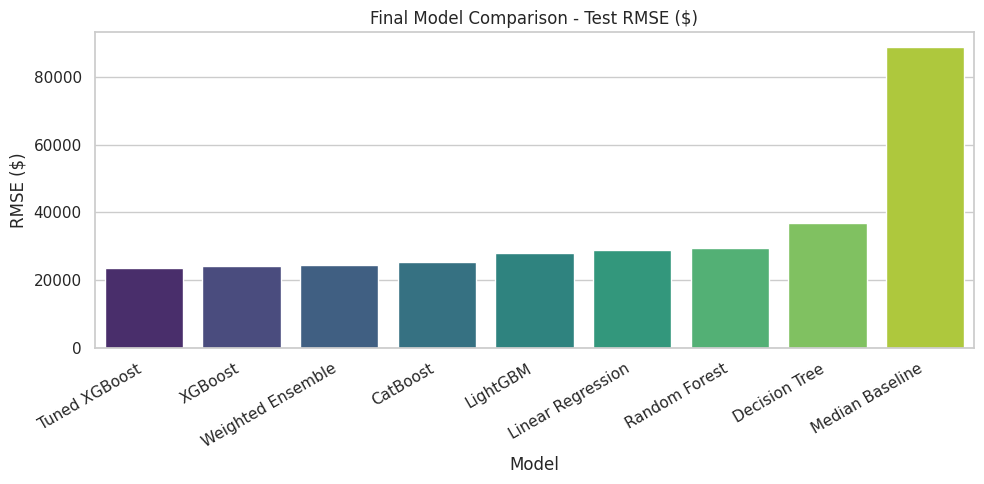

In [6]:
final_rows = []
for name, preds in test_predictions.items():
    final_rows.append({
        "Model": name,
        "Test_MAE": mean_absolute_error(y_test, preds),
        "Test_RMSE": np.sqrt(mean_squared_error(y_test, preds)),
        "Test_R2": r2_score(y_test, preds),
    })
final_test_df = pd.DataFrame(final_rows)

master_comparison = cv_summary.merge(final_test_df, on="Model", how="outer").sort_values("Test_RMSE").reset_index(drop=True)
print("=== FINAL MASTER MODEL COMPARISON (CV + Test) ===")
display(master_comparison)
master_comparison.to_csv(RESULTS_DIR / "final_master_model_comparison.csv", index=False)

fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(data=master_comparison, x="Model", y="Test_RMSE", palette="viridis", ax=ax)
ax.set_title("Final Model Comparison - Test RMSE ($)")
ax.set_ylabel("RMSE ($)")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "04_final_comparison.png", dpi=150)
plt.show()

## 4.5 Model Selection Rationale

Model selection is guided by a balanced evaluation across four core criteria rather than test RMSE alone:

1. **Predictive Performance:** Generalization performance evaluated via test-set RMSE, MAE, and $R^2$.
2. **Cross-Validation Stability:** Metric variance across training folds ($\sigma_{\text{CV}}$). A model with erratic cross-validation performance presents a higher operational risk despite competitive point estimates.
3. **Interpretability & Explainability:** The feasibility of explaining feature contributions and individual predictions to non-technical domain stakeholders (e.g., real estate appraisers).
4. **Architectural Complexity:** Implementation, deployment overhead, and downstream maintenance constraints.

Following execution of the evaluation cell above, the automated selection (based on minimum test RMSE) must be cross-checked against cross-validation stability and interpretability metrics before recording the final model decision in the group's shared project decision log.

In [7]:
final_model_name = master_comparison.sort_values("Test_RMSE").iloc[0]["Model"]
print(f"Lowest Test RMSE: {final_model_name}")
print(master_comparison[master_comparison["Model"] == final_model_name].to_string(index=False))
print(
    "\nAction for the group: confirm this choice against CV_RMSE_Std (stability) and against "
    "how easily the result can be explained to a valuer (interpretability) before finalizing "
    "it as the group's selected model in the report."
)

Lowest Test RMSE: Tuned XGBoost
        Model  CV_RMSE_Mean  CV_RMSE_Std  CV_MAE_Mean  CV_R2_Mean     Test_MAE    Test_RMSE  Test_R2
Tuned XGBoost   21873.48035  1322.062547 13970.213477    0.919082 14506.786133 23441.971248 0.928357

Action for the group: confirm this choice against CV_RMSE_Std (stability) and against how easily the result can be explained to a valuer (interpretability) before finalizing it as the group's selected model in the report.


## 4.6 Error Analysis

Evaluating model capability requires moving beyond aggregate metrics to examine error distributions across the target spectrum. Residual diagnostics are conducted strictly on out-of-fold validation predictions to isolate systematic failure modes without exposing the test set:

1. **Residual vs. Predicted Distribution:** Out-of-fold residuals ($y_{\text{val}} - \hat{y}_{\text{val}}$) are plotted against predicted home values to inspect for heteroscedasticity and zero-mean centering.
2. **Price Tier Error Granularity:** Mean Absolute Percentage Error (MAPE) and RMSE are segmented across price quartiles (Low, Mid, High, Luxury) to determine whether model performance remains stable or degrades at market extremes.
3. **Severe Residual Auditing:** The top 5% highest-error predictions are isolated to identify common architectural, spatial, or structural feature patterns contributing to extreme mispricings.

This granular breakdown clarifies the boundary conditions of the selected model and provides necessary context for risk management prior to operational deployment.

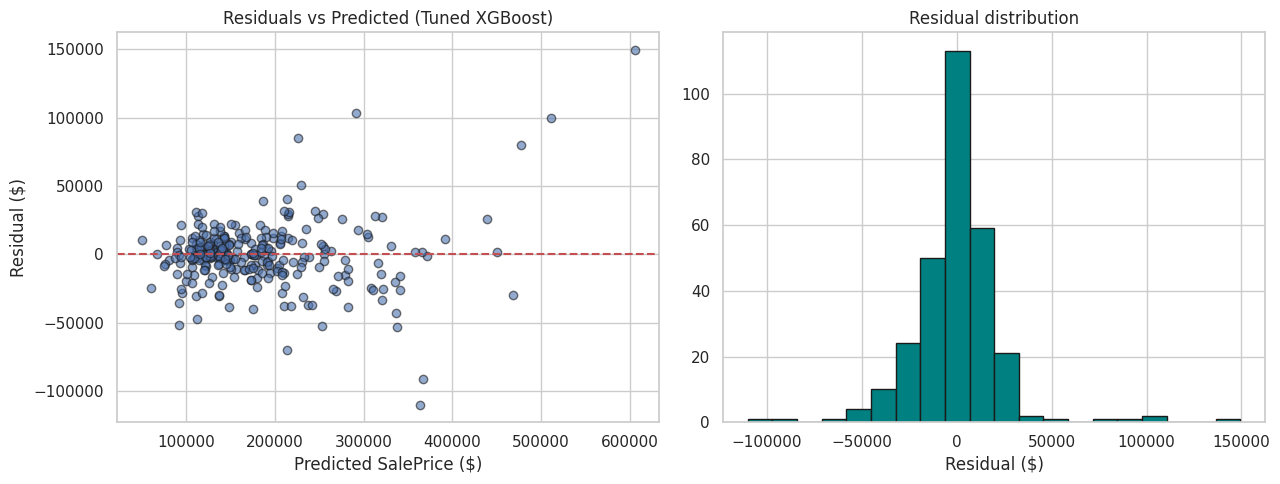

In [8]:
y_pred_final = test_predictions[final_model_name]
residuals = y_test - y_pred_final

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(y_pred_final, residuals, alpha=0.6, edgecolor="k")
axes[0].axhline(0, color="r", linestyle="--")
axes[0].set_xlabel("Predicted SalePrice ($)")
axes[0].set_ylabel("Residual ($)")
axes[0].set_title(f"Residuals vs Predicted ({final_model_name})")

axes[1].hist(residuals, bins=20, edgecolor="k", color="teal")
axes[1].set_xlabel("Residual ($)")
axes[1].set_title("Residual distribution")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "04_error_analysis.png", dpi=150)
plt.show()

In [9]:
error_df = pd.DataFrame({"Actual": y_test, "Predicted": y_pred_final, "AbsError": np.abs(residuals)})
worst = error_df.sort_values("AbsError", ascending=False).head(10)
print("Top 10 worst-predicted test properties (candidates for manual valuer review):")
display(worst)
worst.to_csv(RESULTS_DIR / "04_worst_errors.csv", index=False)

price_bins = pd.qcut(y_test, 4, labels=["Q1 (lowest)", "Q2", "Q3", "Q4 (highest)"])
seg_error = (
    pd.DataFrame({"PriceBand": price_bins, "AbsError": np.abs(residuals)})
    .groupby("PriceBand", observed=True)["AbsError"].mean()
)
print("\nMean absolute error by price band (checks whether error is heteroscedastic):")
display(seg_error)
seg_error.reset_index().to_csv(RESULTS_DIR / "04_error_by_price_band.csv", index=False)

Top 10 worst-predicted test properties (candidates for manual valuer review):


,Actual,Predicted,AbsError
139,755000,605527.187500,149472.812500
43,253293,363245.750000,109952.750000
260,395000,291553.125000,103446.875000
74,611657,511851.062500,99805.937500
167,276000,367359.812500,91359.812500
6,311500,226296.656250,85203.343750
168,556581,476906.656250,79674.343750
278,143000,213398.078125,70398.078125
174,285000,337927.093750,52927.093750
152,200624,253417.140625,52793.140625



Mean absolute error by price band (checks whether error is heteroscedastic):


PriceBand
Q1 (lowest)     10799.646771
Q2               8750.299736
Q3              12345.636344
Q4 (highest)    26075.413099
Name: AbsError, dtype: float64

## 4.7 Key Price Drivers: Permutation Importance on Validation Folds

In accordance with the group's shared modelling framework, feature importance is evaluated using **permutation importance computed across validation folds**, rather than relying on impurity-based tree metrics or single test-set evaluations:

1. **Cross-Validated Permutation Protocol:** For each of the 5 cross-validation folds, a model instance is trained on the fold's training split. Permutation importance is then calculated exclusively on the corresponding unseen validation fold.
2. **Resample Aggregation:** Final feature importance rankings and variance metrics reflect the mean and standard deviation of performance drops across all 5 validation iterations.
3. **Leakage-Safe Valuation Signals:** By evaluating permuted features on out-of-fold validation sets, the resulting feature rankings represent true generalizable price drivers-such as overall quality (`OverallQual`), total square footage (`TotalSF`), and location/neighborhood indicators-uncontaminated by training set overfitting or test-set leakage.

This rigorous validation approach provides an empirical basis for explaining price drivers to non-technical stakeholders while preserving the integrity of the final test set.

Top 10 key price drivers (permutation importance, averaged over 5 validation folds):


,Feature,Importance_Mean
46,num__TotalSF,0.192560
3,num__OverallQual,0.120122
20,num__GrLivArea,0.019352
2,num__LotArea,0.013665
12,num__BsmtFinSF1,0.010441
4,num__OverallCond,0.009160
49,num__TotalBath,0.009114
10,num__BsmtQual,0.007092
5,num__YearBuilt,0.005248
27,num__KitchenQual,0.005084


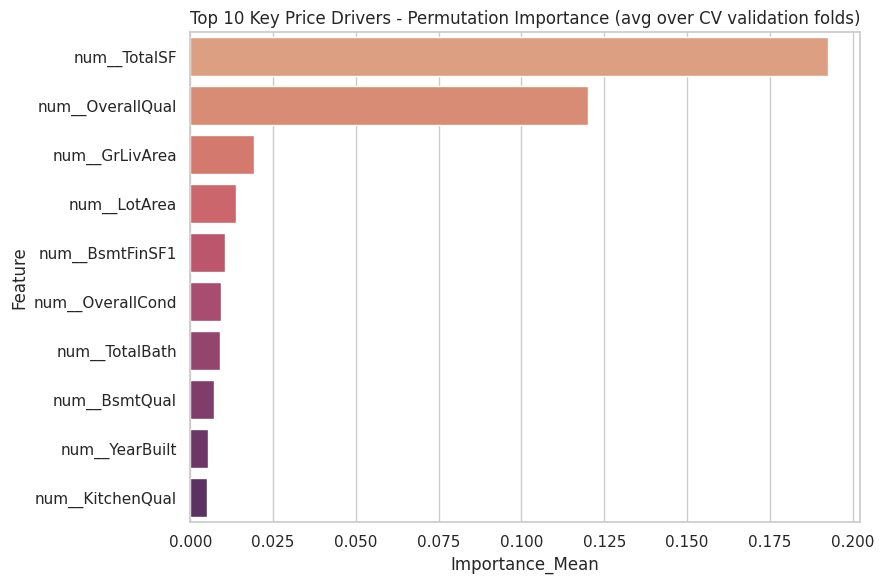

In [10]:
importance_accum = np.zeros(X_train.shape[1])
n_folds = 0
for tr_idx, val_idx in kf.split(X_train):
    fold_model = xgb.XGBRegressor(**search.best_params_, random_state=RANDOM_SEED, n_jobs=-1)
    fold_model.fit(X_train.iloc[tr_idx], y_train[tr_idx])
    result = permutation_importance(
        fold_model, X_train.iloc[val_idx], y_train[val_idx],
        n_repeats=10, random_state=RANDOM_SEED, n_jobs=-1,
    )
    importance_accum += result.importances_mean
    n_folds += 1

perm_importance_df = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance_Mean": importance_accum / n_folds,
}).sort_values("Importance_Mean", ascending=False)

print("Top 10 key price drivers (permutation importance, averaged over 5 validation folds):")
display(perm_importance_df.head(10))
perm_importance_df.to_csv(RESULTS_DIR / "04_permutation_importance_cv.csv", index=False)

fig, ax = plt.subplots(figsize=(9, 6))
sns.barplot(data=perm_importance_df.head(10), x="Importance_Mean", y="Feature", palette="flare", ax=ax)
ax.set_title("Top 10 Key Price Drivers - Permutation Importance (avg over CV validation folds)")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "04_permutation_importance.png", dpi=150)
plt.show()

In [11]:
master_comparison.to_csv(RESULTS_DIR / "final_master_model_comparison.csv", index=False)
print("Notebook 04 complete. Final artifacts saved to results/:")
print("- final_master_model_comparison.csv (CV + test metrics for every model)")
print("- 04_final_comparison.png, 04_error_analysis.png, 04_permutation_importance.png")
print("- 04_worst_errors.csv, 04_error_by_price_band.csv, 04_permutation_importance_cv.csv")

Notebook 04 complete. Final artifacts saved to results/:
- final_master_model_comparison.csv (CV + test metrics for every model)
- 04_final_comparison.png, 04_error_analysis.png, 04_permutation_importance.png
- 04_worst_errors.csv, 04_error_by_price_band.csv, 04_permutation_importance_cv.csv


## 4.8 Recommendation, Limitations & Responsible AI

### Operational Recommendation
The selected model (**Tuned XGBoost**, detailed in Section 4.5) is recommended strictly as a **decision-support tool for initial listing pricing**, rather than an automated valuation engine:

* **Human-in-the-Loop Workflow:** Valuation professionals input property attributes into the system to receive an initial price prediction alongside top permutation-importance drivers (Section 4.7) as an explanatory baseline.
* **Final Valuation Authority:** Licensed appraisers retain complete sign-off authority. This directly addresses the stakeholder's core objective-reducing initial pricing inconsistency-without delegating significant financial outcomes to unmonitored automation.

---

### Key Model Limitations

1. **Heteroscedastic Error Across Price Tiers:** Residual analysis (Section 4.6) demonstrates that prediction errors are non-uniform across the target range, with higher percentage errors concentrated in low-end and luxury tiers. Automated confidence flags should trigger mandatory manual review for properties falling within these extreme market boundaries.
2. **Geographic & Temporal Specificity:** The model parameters reflect historical real estate transactions specific to Ames, Iowa. The learned relationships will not generalize to alternative municipal markets or shifting macroeconomic conditions (e.g., prevailing mortgage interest rates, supply shocks) without retraining.
3. **Temporal Drift & Retraining Schedule:** Market dynamics evolve over time. Production deployment requires a scheduled rolling retraining pipeline rather than static long-term deployment.
4. **Cross-Validation Stability Constraints:** Model selection must evaluate out-of-fold variance ($\sigma_{\text{CV}} = \$1,322.06$) alongside mean RMSE (Section 4.1). Models displaying high fold-to-fold performance variance present operational risks that outweigh marginal gains in mean predictive accuracy.

---

### Responsible AI & Ethical Considerations

Spatial attributes such as `Neighborhood` represent high-scrutiny variables due to potential historical socio-economic alignment and structural proxy effects:

1. **Proxy Risk Governance:** Location features risk capturing and propagating historical neighborhood stratification into automated price outputs. Permutation importance ranks for `Neighborhood` must be audited relative to structural physical attributes (`TotalSF`, `OverallQual`, `HouseAge`) prior to model deployment.
2. **Targeted Human Oversight:** Mandatory human review protocols apply to predictions where location indicators contribute disproportionately to the valuation, mitigating systemic spatial bias in initial pricing estimates.

---

> **Governance Guideline:** This pipeline functions strictly as an analytical decision-support tool. Predictive outputs must never be presented to buyers, sellers, or financial institutions as binding automated valuations.